In [10]:
# requires transformers>=5.2:  pip install -U "transformers>=5.2"
from transformers import pipeline
import torch

# Load the model
classifier = pipeline(
    "text-classification",
    model="bhadresh-savani/bert-base-go-emotion",
    top_k=5,
    trust_remote_code=True
)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [11]:
text = "I am so happy and excited about this opportunity!"
predictions = classifier(text)

# Print top 5 detected emotions
sorted_preds = sorted(predictions[0], key=lambda x: x['score'], reverse=True)
top_5 = sorted_preds[:5]

print("\nTop 5 emotions detected:")
for pred in top_5:
    print(f"\t{pred['label']:10s} : {pred['score']:.3f}")

# Example output:
# Top 5 emotions detected:
#        excitement : 0.885
#        joy        : 0.753
#        admiration : 0.015
#        love       : 0.015
#        gratitude  : 0.009


Top 5 emotions detected:
	excitement : 0.584
	joy        : 0.245
	admiration : 0.022
	love       : 0.021
	gratitude  : 0.018


True
AUC Score for admiration: 0.9562186239517135
AUC Score for amusement: 0.9879577295323954
AUC Score for anger: 0.9388337380305252
AUC Score for annoyance: 0.8925384276483257
AUC Score for approval: 0.8356401500609539
AUC Score for caring: 0.9097169732090367
AUC Score for confusion: 0.9479491202371481
AUC Score for curiosity: 0.9612361119859347
AUC Score for desire: 0.9537303405237718
AUC Score for disappointment: 0.8778462009650096
AUC Score for disapproval: 0.9144608483581569
AUC Score for disgust: 0.9554071785061742
AUC Score for embarrassment: 0.9216266359123503
AUC Score for excitement: 0.9441856987592365
AUC Score for fear: 0.9843033205343917
AUC Score for gratitude: 0.995814487236901
AUC Score for grief: 0.9703621718010207
AUC Score for joy: 0.9569186366070397
AUC Score for love: 0.9893472131577626
AUC Score for nervousness: 0.9344286036108519
AUC Score for optimism: 0.9504229472746931
AUC Score for pride: 0.9045809462206617
AUC Score for realization: 0.8323127342046508
AUC S

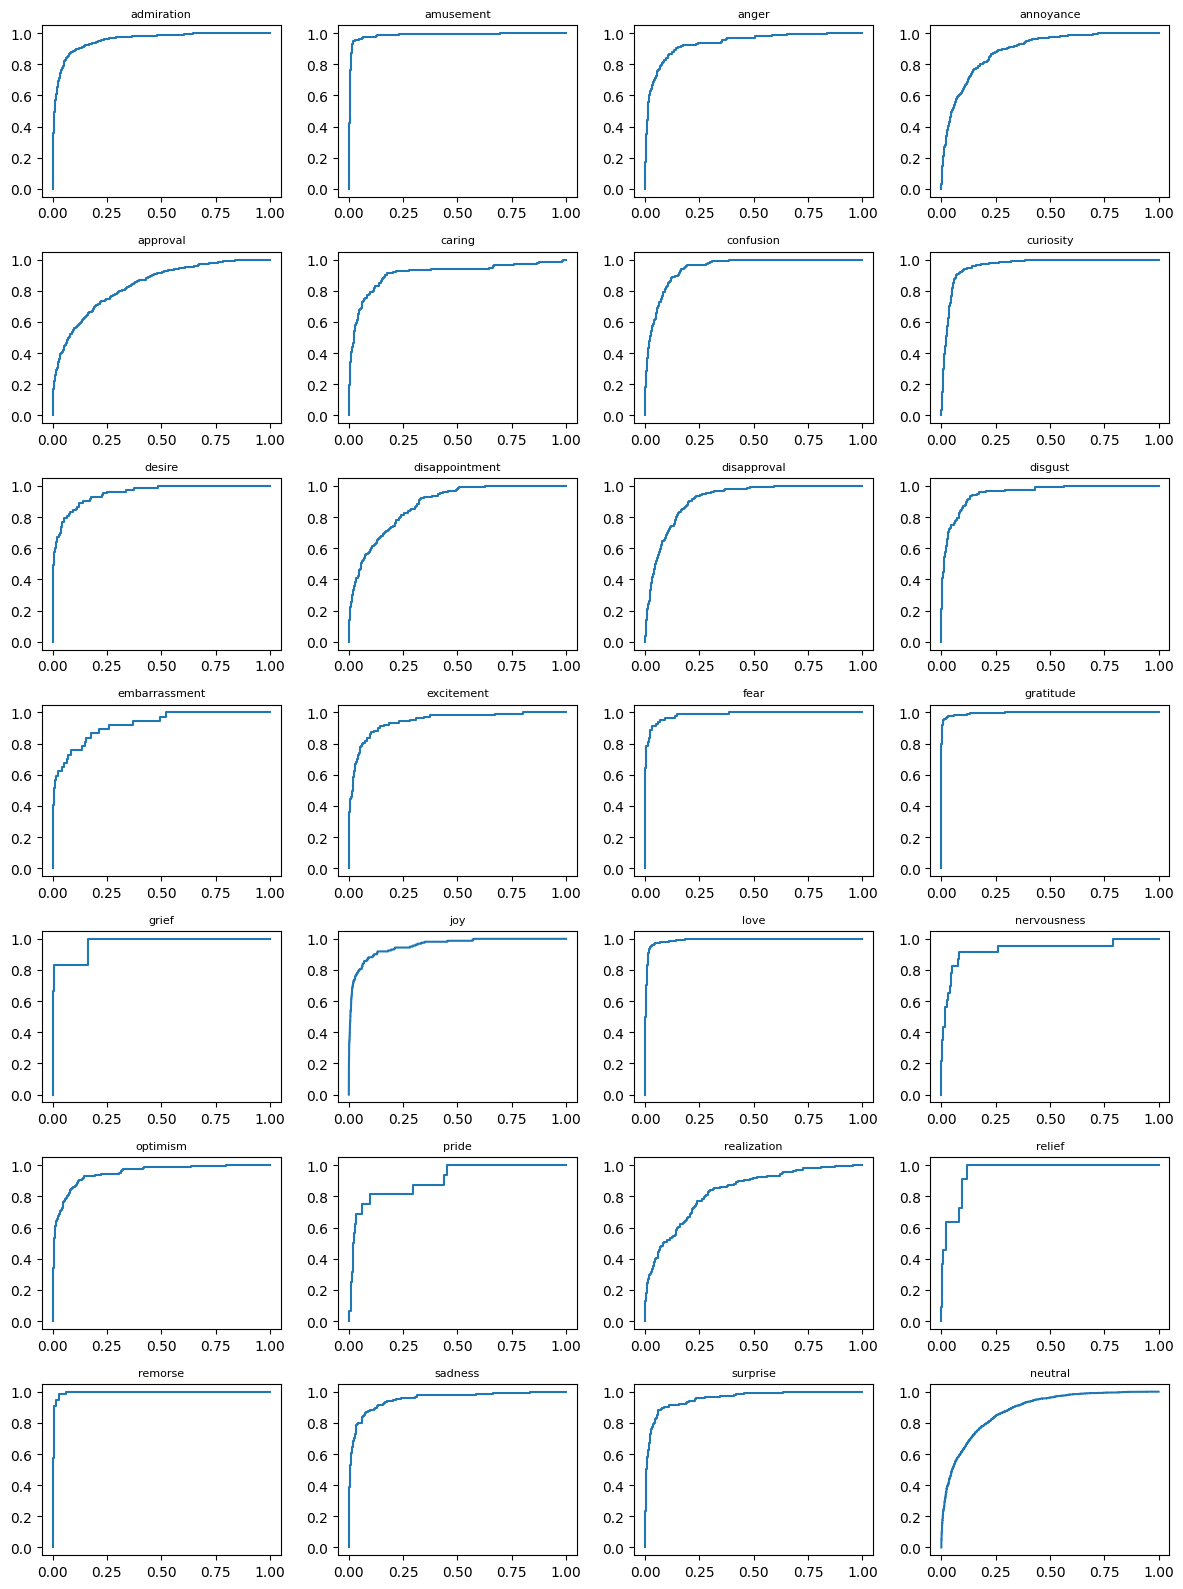

Threshold for admiration: 0.30000000000000004
Corresponding F1 Score: 0.7350993377483444
Threshold for amusement: 0.35
Corresponding F1 Score: 0.7986906710310966
Threshold for anger: 0.2
Corresponding F1 Score: 0.5265588914549654
Threshold for annoyance: 0.15000000000000002
Corresponding F1 Score: 0.4469135802469136
Threshold for approval: 0.15000000000000002
Corresponding F1 Score: 0.40328253223915594
Threshold for caring: 0.15000000000000002
Corresponding F1 Score: 0.535483870967742
Threshold for confusion: 0.15000000000000002
Corresponding F1 Score: 0.4169014084507042
Threshold for curiosity: 0.2
Corresponding F1 Score: 0.5641838351822503
Threshold for desire: 0.25
Corresponding F1 Score: 0.6060606060606061
Threshold for disappointment: 0.15000000000000002
Corresponding F1 Score: 0.35714285714285715
Threshold for disapproval: 0.15000000000000002
Corresponding F1 Score: 0.4717285945072698
Threshold for disgust: 0.2
Corresponding F1 Score: 0.4717948717948718
Threshold for embarrassmen

In [12]:
from datasets import load_dataset
import numpy as np
from sklearn.metrics import f1_score, roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# setting up
ds = load_dataset("google-research-datasets/go_emotions", "simplified")
# take the model and tokenizer out of the pipeline
model, tokenizer = classifier.model, classifier.tokenizer
k = model.config.num_labels
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device).eval()
# emotion names in the dataset's order, used for printing
names = ds["train"].features["labels"].feature.names
model_names = [model.config.id2label[i] for i in range(k)]
print(model_names == names)

# turn dataset's labels into grid
def labels(d):
    y = np.zeros((d.num_rows, k))
    for i, labs in enumerate(d["labels"]):
        y[i, labs] = 1
    return y

# BERT
def probs(texts, bs=64):
    out = []
    for i in range(0, len(texts), bs):
        b = tokenizer(texts[i:i+bs], return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
        with torch.no_grad():
            # softmax; not sigmoid
            out.append(torch.softmax(model(**b).logits, dim=-1).cpu().numpy())
    return np.vstack(out)

# answer key
vy, ty = labels(ds["validation"]), labels(ds["test"])
# BERT's probabilities
vp, tp = probs(ds["validation"]["text"]), probs(ds["test"]["text"])
# reorder columns if the model's label order differs from the dataset's
if model_names != names:
    idx = [model_names.index(n) for n in names]
    vp, tp = vp[:, idx], tp[:, idx]

# roc curves and auc on test
fig, axs = plt.subplots(7, 4, figsize=(12, 16))
for i in range(k):
    fpr, tpr, _ = roc_curve(ty[:, i], tp[:, i])
    # 28 emotions fill a 7x4 grid, so row = i // 4 and column = i % 4
    axs[i // 4, i % 4].plot(fpr, tpr)
    axs[i // 4, i % 4].set_title(names[i], fontsize=8)
    print(f"AUC Score for {names[i]}: {roc_auc_score(ty[:, i], tp[:, i])}")
plt.tight_layout()
plt.show()

# cutoff per emotion (using validation)
grid = np.linspace(0.1, 0.9, 17)
th = []
for i in range(k):
    # f1 at each candidate cutoff for this emotion
    f1s = [f1_score(vy[:, i], vp[:, i] >= t) for t in grid]
    best = int(np.argmax(f1s))
    th.append(grid[best])
    print(f"Threshold for {names[i]}: {grid[best]}")
    print(f"Corresponding F1 Score: {f1s[best]}")

# f1 on test using the cutoffs from validation
f1 = []
for i in range(k):
    f1.append(f1_score(ty[:, i], tp[:, i] >= th[i]))
    print(f"F1 Scores on Test Data for {names[i]}: {f1[i]}")
# every emotion counts equally
print(f"\nMacro F1 Score: {np.mean(f1)}")